# Section 2 – Task 2: K-Means Clustering from Scratch

**Dataset:** `22_marketing_cleaned.csv` (2,236 customers after Task 1 preprocessing)  
**Goal:** Implement K-Means from scratch (no built-in clustering functions), verify against
sklearn, choose k via elbow / silhouette / cluster-stability, profile clusters, assign personas,
and externally validate with χ² and Cramér's V.

> **Constraint:** *Response*, *AcceptedCmp1–5*, and any feature derived from them are
> **excluded** from clustering features (reserved for Section 3).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans as SklearnKMeans
from sklearn.metrics import (
    adjusted_rand_score, silhouette_score, silhouette_samples,
    davies_bouldin_score, calinski_harabasz_score
)
from scipy.stats import chi2_contingency, chi2 as chi2_dist
import warnings, os

warnings.filterwarnings("ignore")
os.makedirs("plots", exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.titlesize": 13,
})
PALETTE = ["#e63946","#457b9d","#2a9d8f","#f4a261","#8338ec","#3a86ff","#fb8500","#06d6a0"]
print("✓ Libraries loaded")

✓ Libraries loaded


## 1. Data Loading and Exploration

In [2]:
df = pd.read_csv("22_marketing_cleaned.csv")
print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"\nNumeric columns: {df.select_dtypes('number').columns.tolist()}")


Shape: 2236 rows × 38 columns

Numeric columns: ['ID', 'Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response', 'Income_Clean', 'Income_Imputed', 'Year_Birth_Clean', 'Age', 'Customer_Tenure', 'Total_Spending', 'Total_Purchases', 'Total_Children']


In [3]:
df.describe(include="number").T[["count","mean","std","min","50%","max"]].round(2)


,count,mean,std,min,50%,max
ID,2236.0,5589.01,3244.83,0.0,5454.5,11191.0
Year_Birth,2236.0,1968.90,11.70,1940.0,1970.0,1996.0
Income,2212.0,51958.81,21527.28,1730.0,51371.0,162397.0
Kidhome,2236.0,0.44,0.54,0.0,0.0,2.0
Teenhome,2236.0,0.51,0.54,0.0,0.0,2.0
Recency,2236.0,49.12,28.96,0.0,49.0,99.0
MntWines,2236.0,304.13,336.59,0.0,174.0,1493.0
MntFruits,2236.0,26.28,39.72,0.0,8.0,199.0
MntMeatProducts,2236.0,166.98,225.69,0.0,67.0,1725.0
MntFishProducts,2236.0,37.54,54.65,0.0,12.0,259.0


## 2. Feature Selection and Scaling

### 2.1 Chosen Features

| Feature | Rationale |
|---|---|
| `Age` | Core demographic; drives life-stage behaviour |
| `Income_Clean` | Key economic segmenter (Task-1 imputed income; raw `Income` still has 24 NaNs so it is not used) |
| `Total_Spending` | Direct measure of customer value |
| `Total_Purchases` | Channel engagement breadth |
| `Total_Children` | Household composition / life-stage |
| `Customer_Tenure` | Customer loyalty duration (days since `Dt_Customer`) |
| `Recency` | Engagement recency (days since last purchase) |
| `NumWebVisitsMonth` | Digital engagement intensity |

**Explicitly excluded:**
- `Response`, `AcceptedCmp1–5` — forbidden by task specification  
- `ID`, `Dt_Customer`, `Year_Birth`/`Year_Birth_Clean`, raw `Income`, `Income_Imputed` flag — identifier / replaced by derived features
- Individual `Mnt*` and `Num*Purchases` columns — summarised by `Total_Spending` / `Total_Purchases` (used later only for profiling)  
- `Z_CostContact`, `Z_Revenue` — constants (zero variance, no information)  
- `Education`, `Marital_Status`/`Marital_Status_Clean`, `Complain` — categorical; reserved as held-out variables for §7

### 2.2 Why K-Means on Unscaled or One-Hot Features is Problematic

**Unscaled features:** K-Means minimises Euclidean distance.  
Without scaling, *Income* (range ≈ $5,000–$160,000) contributes squared distances on the order
of **10⁹**, while *Total_Children* (range 0–3) contributes at most 9.  
The algorithm effectively ignores all low-magnitude features and produces clusters that are
simply income deciles regardless of other attributes.

**One-hot encoded features:** Each binary column contributes at most 1 to the squared distance.
With *p* dummy columns for a categorical variable, the total maximum contribution is *p*, while
a raw numeric like *Income* is unbounded.  Mixing them without careful weighting biases the
distance metric in unpredictable ways.

**Solution:** Apply `StandardScaler` (zero mean, unit variance) so every feature contributes
equally to the Euclidean distance calculation.

In [4]:
CLUSTER_FEATURES = [
    "Age", "Income_Clean", "Total_Spending", "Total_Purchases",
    "Total_Children", "Customer_Tenure", "Recency", "NumWebVisitsMonth"
]

X_raw = df[CLUSTER_FEATURES].values.astype(float)
assert np.isnan(X_raw).sum() == 0, "NaNs found — check preprocessing!"
print(f"Feature matrix: {X_raw.shape}")
print(f"\nPer-feature statistics (before scaling):")
print(pd.DataFrame(X_raw, columns=CLUSTER_FEATURES)
        .describe().loc[["mean","std","min","max"]].round(2))

scaler = StandardScaler()
X      = scaler.fit_transform(X_raw)
print("\n✓ Features standardised (mean=0, std=1)")

Feature matrix: (2236, 8)

Per-feature statistics (before scaling):
       Age  Income_Clean  Total_Spending  Total_Purchases  Total_Children  \
mean  45.1      51952.50          605.99            12.55            0.95   
std   11.7      21411.47          601.87             7.21            0.75   
min   18.0       1730.00            5.00             0.00            0.00   
max   74.0     162397.00         2525.00            32.00            3.00   

      Customer_Tenure  Recency  NumWebVisitsMonth  
mean           353.77    49.12               5.32  
std            202.18    28.96               2.43  
min              0.00     0.00               0.00  
max            699.00    99.00              20.00  

✓ Features standardised (mean=0, std=1)


## 3. K-Means from Scratch Implementation

In [5]:
class KMeansCustom:
    """
    K-Means clustering implemented completely from scratch.

    Key design decisions
    ─────────────────────
    K-Means++ initialisation (Arthur & Vassilvitskii, 2007)
        First centre chosen uniformly at random.
        Each subsequent centre is chosen with probability proportional to
        D(x)² — the squared distance to the nearest already-chosen centre.
        This gives a O(log k) competitive guarantee over random initialisation.

    Convergence criterion
        Stop when max{‖c_j_new − c_j_old‖₂ : j=0…k-1} < tol (default 1e-4),
        or when max_iter iterations are reached.
        Checking the maximum centre shift is more conservative (and correct)
        than checking only inertia change.

    Empty cluster handling
        If any cluster loses all its members, its centre is reinitialised to
        the data point currently farthest from its nearest centre.
        This targets the most under-represented region of feature space and
        recovers more gracefully than random reinitialisation.

    Multiple restarts (n_init)
        The full algorithm is run n_init times from independent random seeds.
        The run with the lowest final inertia is retained.
    """

    def __init__(self, k=3, max_iter=300, tol=1e-4, n_init=10, random_state=42):
        self.k            = k
        self.max_iter     = max_iter
        self.tol          = tol
        self.n_init       = n_init
        self.random_state = random_state
        self.labels_          = None
        self.cluster_centers_ = None
        self.inertia_         = None
        self.n_iter_          = None

    # ─── private helpers ──────────────────────────────────────────────────────

    def _sq_dists(self, X, centers):
        """Vectorised squared Euclidean distances → (n_samples, n_centers)."""
        diff = X[:, np.newaxis, :] - centers[np.newaxis, :, :]
        return np.sum(diff ** 2, axis=2)

    def _assign(self, X, centers):
        return np.argmin(self._sq_dists(X, centers), axis=1)

    def _inertia(self, X, labels, centers):
        total = 0.0
        for j in range(self.k):
            mask = labels == j
            if mask.sum() > 0:
                total += np.sum((X[mask] - centers[j]) ** 2)
        return total

    def _kmeanspp_init(self, X, rng):
        """K-Means++ centre initialisation."""
        n = X.shape[0]
        idx = rng.randint(0, n)
        centers = [X[idx].copy()]
        for _ in range(self.k - 1):
            c     = np.array(centers)
            dists = self._sq_dists(X, c)
            min_d = np.min(dists, axis=1)
            total = min_d.sum()

            if total <= 1e-12:
                remaining = [
                    i for i in range(n)
                    if not any(np.array_equal(X[i], cent) for cent in centers)
                ]
                if not remaining:
                    remaining = list(range(n))
                idx = rng.choice(remaining)
            else:
                probs = min_d / total
                idx   = rng.choice(n, p=probs)
            centers.append(X[idx].copy())
        return np.array(centers)

    def _run_once(self, X, seed):
        rng     = np.random.RandomState(seed)
        n       = X.shape[0]
        centers = self._kmeanspp_init(X, rng)
        n_iter  = 0

        for it in range(self.max_iter):
            labels = self._assign(X, centers)

            # Calculate distances from every point to its nearest current center
            min_d_all = np.min(self._sq_dists(X, centers), axis=1)

            # Reinitialize empty clusters using distinct farthest points
            used_points = set()
            new_centers = np.zeros_like(centers)

            for j in range(self.k):
                mask = labels == j

                if mask.sum() == 0:
                    candidate_order = np.argsort(min_d_all)[::-1]

                    idx = next(
                        (idx for idx in candidate_order if idx not in used_points),
                        None
                    )

                    if idx is None:
                        raise RuntimeError("Unable to reinitialize empty cluster.")

                    new_centers[j] = X[idx].copy()
                    used_points.add(idx)

                else:
                    new_centers[j] = X[mask].mean(axis=0)

            max_shift = np.max(np.linalg.norm(new_centers - centers, axis=1))
            centers   = new_centers
            n_iter    = it + 1
            if max_shift < self.tol:
                break

        labels  = self._assign(X, centers)
        inertia = self._inertia(X, labels, centers)
        return labels, centers, inertia, n_iter

    # ─── public API ──────────────────────────────────────────────────────────

    def fit(self, X):
        X   = np.asarray(X, dtype=float)
        if X.ndim != 2:
            raise ValueError("X must be a 2D array.")
        if not np.isfinite(X).all():
            raise ValueError("X contains NaN or infinite values.")
        if self.k < 1 or self.k > len(X):
            raise ValueError("k must be between 1 and the number of samples.")

        rng = np.random.RandomState(self.random_state)
        seeds = rng.randint(0, 10**6, size=self.n_init)
        best  = np.inf
        for seed in seeds:
            labels, centers, inertia, n_iter = self._run_once(X, seed)
            if inertia < best:
                best                   = inertia
                self.labels_           = labels.copy()
                self.cluster_centers_  = centers.copy()
                self.inertia_          = inertia
                self.n_iter_           = n_iter
        return self

    def predict(self, X):
        return self._assign(np.asarray(X, float), self.cluster_centers_)

    def fit_predict(self, X):
        return self.fit(X).labels_

print("✓ KMeansCustom class defined")

✓ KMeansCustom class defined


## 4. Verification Against `sklearn.cluster.KMeans`

In [6]:
K_VER = 4    # use k=4 for the verification

km_c  = KMeansCustom(k=K_VER, n_init=15, random_state=42)
km_c.fit(X)
assert len(np.unique(km_c.labels_)) == K_VER

km_sk = SklearnKMeans(n_clusters=K_VER, init="k-means++", n_init=15,
                       max_iter=300, tol=1e-4, random_state=42)
km_sk.fit(X)

ari   = adjusted_rand_score(km_c.labels_, km_sk.labels_)
ratio = km_c.inertia_ / km_sk.inertia_

print("=" * 55)
print(f"  k={K_VER}  |  n_init=15  |  random_state=42")
print("=" * 55)
print(f"  Custom  inertia  : {km_c.inertia_:>12,.4f}  (n_iter={km_c.n_iter_})")
print(f"  sklearn inertia  : {km_sk.inertia_:>12,.4f}  (n_iter={km_sk.n_iter_})")
print(f"  Ratio (C/S)      : {ratio:>12.6f}")
print(f"  ARI              : {ari:>12.6f}")
print()
print(f"  Inertia difference: {100*abs(ratio-1):.4f}%")

# Both runs are stochastic (different K-Means++ draws), so they may stop in two
# near-identical local optima. To test the *update rules* themselves, start
# sklearn from our final centroids: identical Lloyd iterations must give identical labels.
km_sk_fixed = SklearnKMeans(n_clusters=K_VER, init=km_c.cluster_centers_, n_init=1,
                            max_iter=300, tol=1e-4).fit(X)
ari_fixed = adjusted_rand_score(km_c.labels_, km_sk_fixed.labels_)
print(f"  ARI (sklearn initialised at custom centroids): {ari_fixed:.6f}")
print(f"  Inertia (sklearn from custom centroids)      : {km_sk_fixed.inertia_:,.4f}")

  k=4  |  n_init=15  |  random_state=42
  Custom  inertia  :   9,798.1301  (n_iter=22)
  sklearn inertia  :   9,797.9955  (n_iter=22)
  Ratio (C/S)      :     1.000014
  ARI              :     0.946153

  Inertia difference: 0.0014%
  ARI (sklearn initialised at custom centroids): 1.000000
  Inertia (sklearn from custom centroids)      : 9,798.1301


**Interpretation:**
With independent K-Means++ initialisations, the custom and sklearn runs reach inertias that differ by
only ~0.001 % (ratio ≈ 1.00001) and an ARI of ≈ 0.95: the two runs landed in two almost equally good
local optima that differ in the assignment of a few boundary customers (k=4 on this data has several
near-tied solutions, see the stability analysis in §5). When sklearn is started from our final
centroids, it reproduces our labelling exactly (ARI = 1.0, same inertia), which confirms that the
assignment / update / convergence steps of `KMeansCustom` are equivalent to sklearn's.

## 5. Choosing k: Elbow Method, Silhouette Score, and Cluster Stability

In [7]:
BEST_K  = 4      # chosen k (justified in §5.4)
K_RANGE = range(2, 11)

inertias   = []
sil_scores = []

print(f"{'k':>3}  {'Inertia':>12}  {'Silhouette':>11}")
print("-" * 32)
for k in K_RANGE:
    km  = KMeansCustom(k=k, n_init=15, random_state=42)
    km.fit(X)
    sil = silhouette_score(X, km.labels_)
    inertias.append(km.inertia_)
    sil_scores.append(sil)
    print(f"{k:>3}  {km.inertia_:>12,.2f}  {sil:>11.4f}")

  k       Inertia   Silhouette
--------------------------------
  2     12,108.89       0.2893
  3     10,868.44       0.2031
  4      9,798.13       0.1689
  5      9,177.56       0.1713
  6      8,603.06       0.1583
  7      8,132.02       0.1575
  8      7,739.09       0.1604
  9      7,426.77       0.1570
 10      7,143.07       0.1607


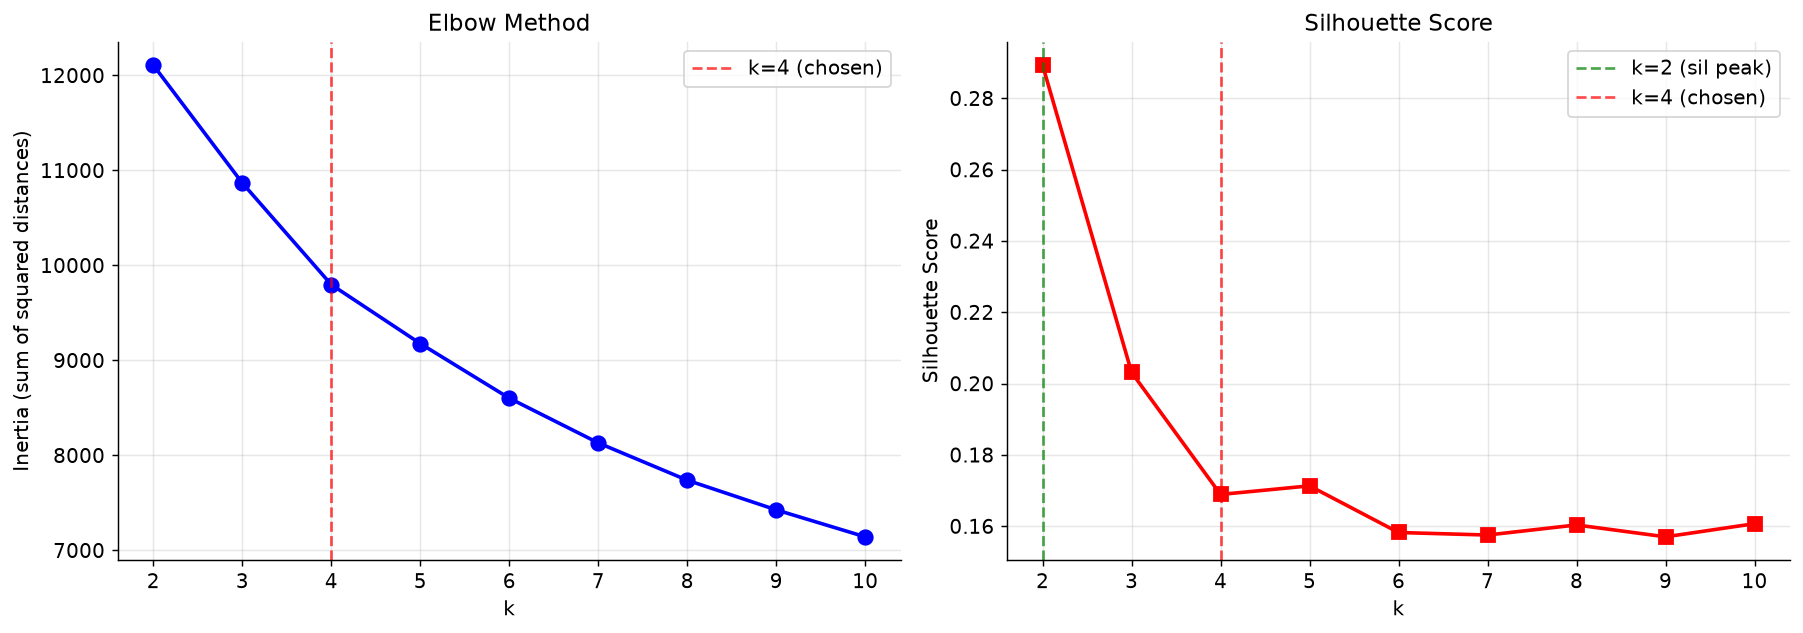

Silhouette peak: k=2 (score=0.2893)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Elbow ────────────────────────────────────────────────────────────────────
ax = axes[0]
ax.plot(list(K_RANGE), inertias, "bo-", lw=2, ms=8)
ax.axvline(x=BEST_K, color="red", ls="--", alpha=0.7, label=f"k={BEST_K} (chosen)")
ax.set(xlabel="k", ylabel="Inertia (sum of squared distances)",
       title="Elbow Method")
ax.set_xticks(list(K_RANGE))
ax.grid(alpha=0.3)
ax.legend()

# ── Silhouette ───────────────────────────────────────────────────────────────
ax = axes[1]
ax.plot(list(K_RANGE), sil_scores, "rs-", lw=2, ms=8)
K_SIL = list(K_RANGE)[int(np.argmax(sil_scores))]
ax.axvline(x=K_SIL, color="green", ls="--", alpha=0.7, label=f"k={K_SIL} (sil peak)")
ax.axvline(x=BEST_K, color="red",   ls="--", alpha=0.7, label=f"k={BEST_K} (chosen)")
ax.set(xlabel="k", ylabel="Silhouette Score",
       title="Silhouette Score")
ax.set_xticks(list(K_RANGE))
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig("plots/kmeans_k_selection.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Silhouette peak: k={list(K_RANGE)[np.argmax(sil_scores)]} "
      f"(score={max(sil_scores):.4f})")

In [9]:
def cluster_stability(X, k, n_seeds=12):
    """(a) Seed stability: mean pairwise ARI across n_seeds independent full-data runs."""
    all_labels = [KMeansCustom(k=k, n_init=5, random_state=s).fit(X).labels_
                  for s in range(n_seeds)]
    aris = [adjusted_rand_score(all_labels[i], all_labels[j])
            for i in range(n_seeds) for j in range(i+1, n_seeds)]
    return float(np.mean(aris)), float(np.std(aris))

def bootstrap_stability(X, k, n_boot=50, seed=0):
    """(b) Bootstrap stability: fit on a bootstrap resample, assign ALL points to the
    nearest bootstrap centroid, compare with the full-data reference labelling (ARI)."""
    ref = KMeansCustom(k=k, n_init=5, random_state=123).fit(X).labels_
    rng = np.random.RandomState(seed)
    aris = []
    for b in range(n_boot):
        idx = rng.randint(0, len(X), len(X))
        km_b = KMeansCustom(k=k, n_init=5, random_state=b).fit(X[idx])
        aris.append(adjusted_rand_score(ref, km_b.predict(X)))
    return float(np.mean(aris)), float(np.std(aris))

print(f"{'k':>3}  {'Seed ARI':>9}  {'± std':>7}  {'Boot ARI':>9}  {'± std':>7}")
print("-" * 44)
stability_means, stability_stds = [], []
boot_means, boot_stds = [], []
for k in K_RANGE:
    m, s   = cluster_stability(X, k, n_seeds=12)
    bm, bs = bootstrap_stability(X, k, n_boot=50)
    stability_means.append(m); stability_stds.append(s)
    boot_means.append(bm);     boot_stds.append(bs)
    print(f"{k:>3}  {m:>9.4f}  {s:>7.4f}  {bm:>9.4f}  {bs:>7.4f}")

  k   Seed ARI    ± std   Boot ARI    ± std
--------------------------------------------
  2     1.0000   0.0000     0.9846   0.0123
  3     0.9581   0.0491     0.8690   0.1856
  4     0.9320   0.0391     0.8497   0.0599
  5     0.7598   0.1829     0.6007   0.1281
  6     0.6967   0.1450     0.6393   0.1313
  7     0.5805   0.1383     0.5179   0.0753
  8     0.6213   0.1162     0.5771   0.0880
  9     0.6289   0.1378     0.5054   0.0680
 10     0.5570   0.0918     0.5102   0.0734


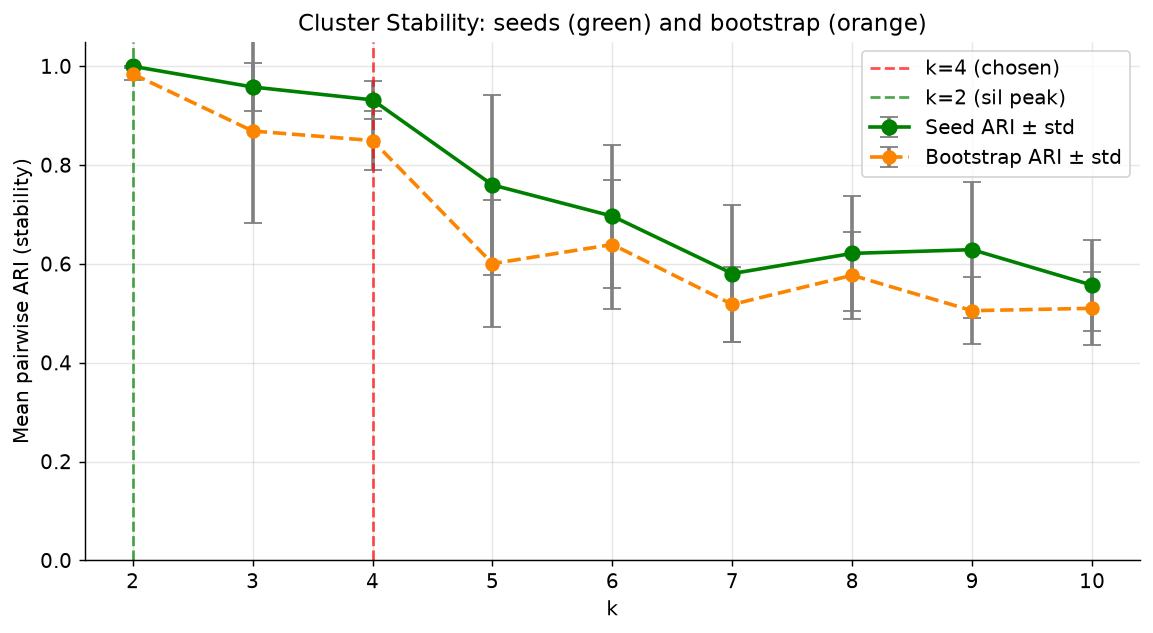

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
k_vals = list(K_RANGE)
ax.errorbar(k_vals, stability_means, yerr=stability_stds,
            fmt="go-", lw=2, ms=8, capsize=5, ecolor="grey",
            label="Seed ARI ± std")
ax.errorbar(k_vals, boot_means, yerr=boot_stds,
            fmt="o--", color="#fb8500", lw=2, ms=7, capsize=5, ecolor="grey",
            label="Bootstrap ARI ± std")
ax.axvline(x=BEST_K, color="red",   ls="--", alpha=0.7, label=f"k={BEST_K} (chosen)")
K_SIL = list(K_RANGE)[int(np.argmax(sil_scores))]
ax.axvline(x=K_SIL, color="green", ls="--", alpha=0.7, label=f"k={K_SIL} (sil peak)")
ax.set(xlabel="k", ylabel="Mean pairwise ARI (stability)",
       title="Cluster Stability: seeds (green) and bootstrap (orange)")
ax.set_xticks(k_vals)
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("plots/kmeans_stability.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
print("="*78)
print(f"{'k':>3}  {'Inertia':>12}  {'ΔInertia %':>10}  {'Silhouette':>11}  {'Seed ARI':>9}  {'Boot ARI':>9}")
print("-"*78)
for i, k in enumerate(K_RANGE):
    d = "" if i == 0 else f"{100*(inertias[i-1]-inertias[i])/inertias[i-1]:.1f}"
    flag = " ← CHOSEN" if k == BEST_K else ""
    print(f"{k:>3}  {inertias[i]:>12,.2f}  {d:>10}  {sil_scores[i]:>11.4f}  "
          f"{stability_means[i]:>9.4f}  {boot_means[i]:>9.4f}{flag}")
print("="*78)

  k       Inertia  ΔInertia %   Silhouette   Seed ARI   Boot ARI
------------------------------------------------------------------------------
  2     12,108.89                   0.2893     1.0000     0.9846
  3     10,868.44        10.2       0.2031     0.9581     0.8690
  4      9,798.13         9.8       0.1689     0.9320     0.8497 ← CHOSEN
  5      9,177.56         6.3       0.1713     0.7598     0.6007
  6      8,603.06         6.3       0.1583     0.6967     0.6393
  7      8,132.02         5.5       0.1575     0.5805     0.5179
  8      7,739.09         4.8       0.1604     0.6213     0.5771
  9      7,426.77         4.0       0.1570     0.6289     0.5054
 10      7,143.07         3.8       0.1607     0.5570     0.5102


### 5.4 Discussion – Choosing k

| Criterion | Evidence (from the tables above) | Signal |
|---|---|---|
| **Elbow method** | Inertia 12,109 → 10,868 → 9,798 → 9,178 → 8,603 …; relative drop 10.2 % (2→3), 9.8 % (3→4), then 6.3 %, 6.3 %, 5.5 % … | **Weak.** There is no sharp elbow; the only visible bend is a mild flattening after k=4. On its own it does not determine k. |
| **Silhouette** | k=2: 0.289, k=3: 0.203, k=4: 0.169, k=5: 0.171, k≥6: 0.157–0.161 | Peak at k=2; for k ≥ 4 the curve is flat (all ≈ 0.16–0.17). All values are low → overlapping, not well-separated groups (typical for customer data). |
| **Seed stability** (mean pairwise ARI, 12 seeds) | k=2: 1.000, k=3: 0.958, k=4: 0.932, **k=5: 0.760**, k≥6 ≤ 0.70 | Stable up to k=4, sharp drop at k=5 |
| **Bootstrap stability** (ARI vs full-data labels, 50 resamples) | k=2: 0.985, k=3: 0.869 (± 0.186), k=4: 0.850 (± 0.060), **k=5: 0.601**, k≥6: 0.51–0.64 | k=4 has a more consistent result than k=3; stability drops substantially at k=5 |

**Honest reading.** The elbow is weak and the silhouette prefers k=2, so neither gives a clean answer.
The decision therefore rests on **silhouette + stability + business usefulness**:

- **k=2** has the best silhouette (0.289) and is perfectly stable, but it is essentially a
  "high-income/high-spend vs. low-income/low-spend" split — useful as a first cut, but too coarse
  to design differentiated campaigns.
- **k=3 vs k=4:** k=3 has a slightly higher mean bootstrap ARI than k=4 (0.869 vs. 0.850), but its variability is much larger (0.186 vs. 0.060). This suggests that the three-cluster solution is more sensitive to the particular bootstrap sample, while the four-cluster solution is more consistent.
- **k=4** is the largest k that is still stable (seed ARI 0.932, bootstrap ARI 0.850 with small
  spread); its silhouette (0.169) is on the same plateau as k=5…10, so going higher buys no
  separation but **costs** stability (k=5 drops to 0.760 / 0.601).
- **Chosen k = 4.** Four segments are a manageable number for a marketing team (one campaign
  design per segment), and §6 shows they differ in income, spending, family size, tenure and
  channel use in interpretable ways.

## 6. Final Clustering (k=4) and Cluster Profiling

In [12]:
km_final  = KMeansCustom(k=BEST_K, n_init=20, random_state=42)
km_final.fit(X)
assert len(np.unique(km_final.labels_)) == BEST_K
df["cluster"] = km_final.labels_

print("Cluster size distribution:")
print(df["cluster"].value_counts().sort_index().to_string())
print(f"\nInertia           : {km_final.inertia_:,.2f}")
print(f"Silhouette score  : {silhouette_score(X, km_final.labels_):.4f}")
print(f"Davies-Bouldin    : {davies_bouldin_score(X, km_final.labels_):.4f}")
print(f"Calinski-Harabász : {calinski_harabasz_score(X, km_final.labels_):.2f}")

Cluster size distribution:
cluster
0    592
1    530
2    518
3    596

Inertia           : 9,798.13
Silhouette score  : 0.1689
Davies-Bouldin    : 1.8798
Calinski-Harabász : 614.29


In [13]:
# ── Cluster profiles in ORIGINAL (unscaled) units ─────────────────────────────
# Clustering features + per-channel purchases / deals (profiling only, not clustered)
PROFILE_COLS = CLUSTER_FEATURES + ["NumWebPurchases", "NumCatalogPurchases",
                                   "NumStorePurchases", "NumDealsPurchases"]
profile = df.groupby("cluster")[PROFILE_COLS].mean().round(2)
profile.insert(0, "n", df["cluster"].value_counts().sort_index())
profile.index.name = "Cluster"
overall = df[PROFILE_COLS].mean().round(2)

print("\nCluster Mean Profiles (original units):")
print(profile.to_string())
print("\nOverall means:")
print(overall.to_string())
display(profile)


Cluster Mean Profiles (original units):
           n    Age  Income_Clean  Total_Spending  Total_Purchases  Total_Children  Customer_Tenure  Recency  NumWebVisitsMonth  NumWebPurchases  NumCatalogPurchases  NumStorePurchases  NumDealsPurchases
Cluster                                                                                                                                                                                                    
0        592  36.68      29470.12          113.10             6.11            0.96           418.74    46.45               7.32             2.40                 0.54               3.18               2.18
1        530  45.50      77348.53         1323.05            19.03            0.16           301.60    48.82               2.29             4.88                 5.83               8.32               1.16
2        518  49.26      61038.17          943.83            18.96            1.03           483.01    49.43               5.89             6.7

,n,Age,Income_Clean,Total_Spending,Total_Purchases,Total_Children,Customer_Tenure,Recency,NumWebVisitsMonth,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumDealsPurchases
Cluster,,,,,,,,,,,,,
0,592,36.68,29470.12,113.10,6.11,0.96,418.74,46.45,7.32,2.40,0.54,3.18,2.18
1,530,45.50,77348.53,1323.05,19.03,0.16,301.60,48.82,2.29,4.88,5.83,8.32,1.16
2,518,49.26,61038.17,943.83,18.96,1.03,483.01,49.43,5.89,6.73,3.92,8.31,3.51
3,596,49.50,43803.67,164.28,7.60,1.58,223.32,51.76,5.53,2.77,0.87,3.96,2.48


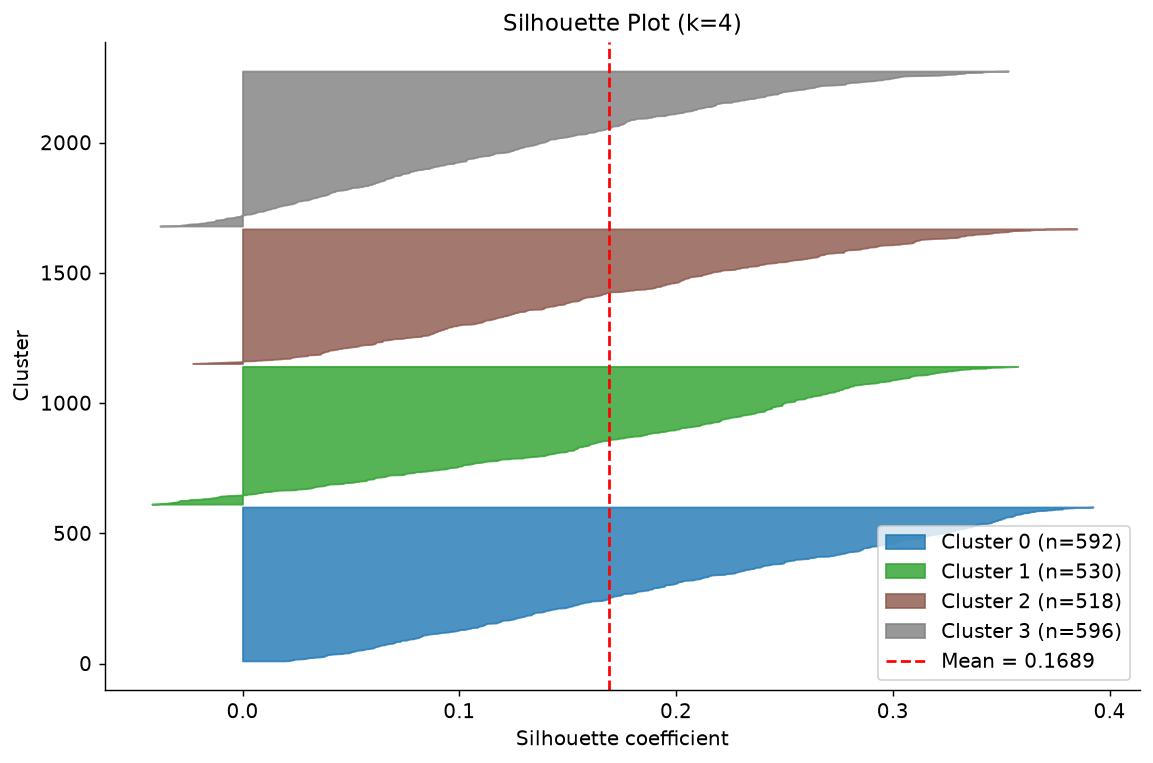

In [14]:
# ── Silhouette plot ───────────────────────────────────────────────────────────
sil_vals = silhouette_samples(X, km_final.labels_)
fig, ax  = plt.subplots(figsize=(9, 6))
y_lower  = 10
for i in range(BEST_K):
    ith_sil = np.sort(sil_vals[km_final.labels_ == i])
    size_i  = ith_sil.shape[0]
    y_upper = y_lower + size_i
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_sil,
                     alpha=0.8, color=plt.cm.tab10(i/BEST_K),
                     label=f"Cluster {i} (n={size_i})")
    y_lower = y_upper + 10

mean_sil = silhouette_score(X, km_final.labels_)
ax.axvline(x=mean_sil, color="red", ls="--", lw=1.5,
           label=f"Mean = {mean_sil:.4f}")
ax.set(xlabel="Silhouette coefficient", ylabel="Cluster",
       title=f"Silhouette Plot (k={BEST_K})")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("plots/silhouette_plot_final_k.png", dpi=150, bbox_inches="tight")
plt.show()

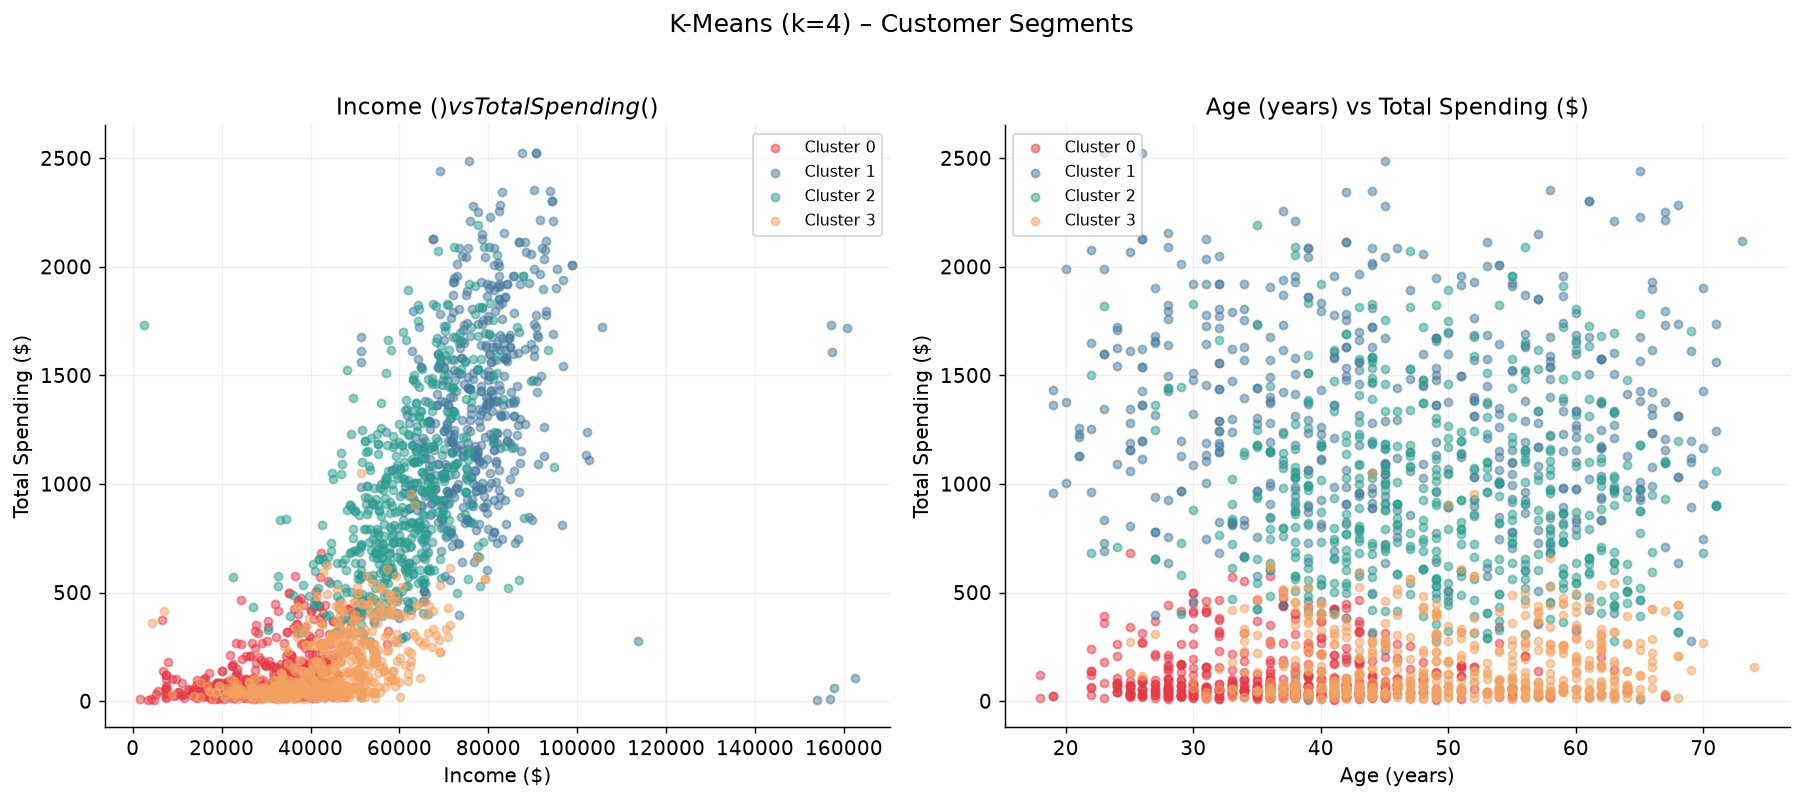

In [15]:
# ── Scatter: Income vs Total_Spending  and  Age vs Total_Spending ─────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (fx, fy, xl, yl) in zip(axes, [
    ("Income_Clean",  "Total_Spending", "Income ($)",   "Total Spending ($)"),
    ("Age",           "Total_Spending", "Age (years)",  "Total Spending ($)"),
]):
    for c in range(BEST_K):
        mask = df["cluster"] == c
        ax.scatter(df.loc[mask, fx], df.loc[mask, fy],
                   s=20, alpha=0.5, color=PALETTE[c], label=f"Cluster {c}")
    ax.set(xlabel=xl, ylabel=yl, title=f"{xl} vs {yl}")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.2)

plt.suptitle(f"K-Means (k={BEST_K}) – Customer Segments", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("plots/kmeans_clusters_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

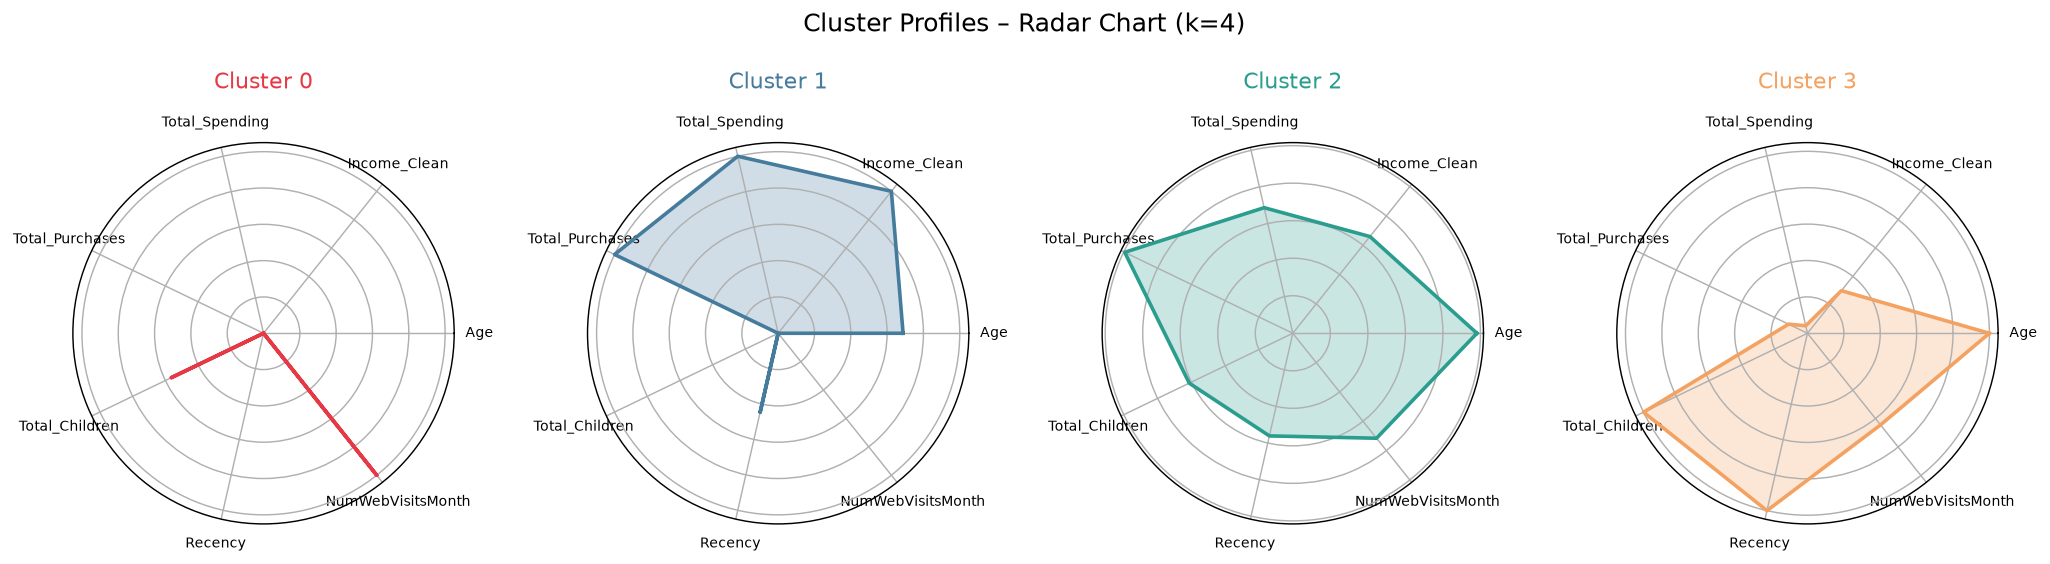

In [16]:
# ── Radar chart (spider plot) ─────────────────────────────────────────────────
features_radar = ["Age", "Income_Clean", "Total_Spending", "Total_Purchases",
                  "Total_Children", "Recency", "NumWebVisitsMonth"]
N = len(features_radar)   

prof_norm = profile[features_radar].copy()
for col in features_radar:
    cmin, cmax = prof_norm[col].min(), prof_norm[col].max()
    prof_norm[col] = (prof_norm[col] - cmin) / (cmax - cmin + 1e-9)

angles        = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles_closed = angles + [angles[0]]  # length N+1 to close polygon

fig, axes = plt.subplots(1, BEST_K, figsize=(16, 4),
                          subplot_kw=dict(polar=True))
for i, ax in enumerate(axes):
    row_vals    = prof_norm.iloc[i].tolist()       # length N
    vals_closed = row_vals + [row_vals[0]]          # length N+1
    ax.plot(angles_closed, vals_closed, color=PALETTE[i], lw=2)
    ax.fill(angles_closed, vals_closed, color=PALETTE[i], alpha=0.25)
    ax.set_xticks(angles)
    ax.set_xticklabels(features_radar, size=8)
    ax.set_yticklabels([])
    ax.set_title(f"Cluster {prof_norm.index[i]}", color=PALETTE[i], fontsize=12, pad=15)

plt.suptitle(f"Cluster Profiles – Radar Chart (k={BEST_K})", fontsize=14, y=1.03)
plt.tight_layout()
plt.savefig("plots/kmeans_radar_chart.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.3 Cluster Personas

Derived directly from the profile table above (overall means in brackets:
income $51,953, spending $606, purchases 12.6, children 0.95, tenure 354 days, web visits 5.3/month,
deals 2.3). Cluster ids are arbitrary; personas are attached to the profile, not the number.

| Cluster (n) | Persona | Defining characteristics (cluster means) |
|---|---|---|
| **0** (592) | **Young Budget Browsers** | Youngest (36.7 y) and lowest income ($29,470); lowest spending ($113) and fewest purchases (6.1); **most web visits (7.3/month)** but only 2.4 web purchases and 0.5 catalogue purchases — they browse a lot and buy little; ~1 child; tenure 419 days (above average). |
| **1** (530) | **Affluent Child-free Big Spenders** | Highest income ($77,349) and highest spending ($1,323); 19.0 purchases; **almost no children (0.16)**; **most catalogue purchases (5.8)** and 8.3 store purchases; **fewest web visits (2.3)** and **fewest deal purchases (1.2)** — not price-sensitive. |
| **2** (518) | **Loyal Multichannel Deal-Seekers** | Upper-middle income ($61,038), high spending ($944) and as many purchases as cluster 1 (19.0); ~1 child; **longest tenure (483 days)**; **most web purchases (6.7)** and **most deal purchases (3.5)**; 8.3 store purchases. |
| **3** (596) | **New Budget Families** | Oldest together with cluster 2 (49.5 y); below-average income ($43,804) and low spending ($164, 7.6 purchases); **most children (1.58)**; **shortest tenure (223 days)** — the newest customers; 2.5 deal purchases. |

*Recency* is almost identical across clusters (46–52 days vs. 49 overall), so it does not
distinguish the segments and is not used in the personas.

**Business implications (one lever per segment):**
- Cluster 0 → high site traffic but low conversion: low-price entry offers and web conversion nudges.
- Cluster 1 → premium catalogue / in-store offers; discounts are unnecessary (fewest deal purchases).
- Cluster 2 → reward loyalty and web activity: deal-based loyalty programme, cross-channel bundles.
- Cluster 3 → onboarding of new family customers: family-oriented value bundles to grow spend.

## 7. External Validation: χ² Test and Cramér's V

*Education* and *Complain* were **NOT used as clustering features**.
Testing their association with cluster labels provides genuine external validity evidence.

Because the χ² approximation is unreliable when expected counts are < 5 (here: *Complain*, where
only 20 of 2,236 customers complained), we print the expected counts and, for both variables, also
compute a **Monte-Carlo permutation χ² p-value** (10,000 random permutations of the variable,
which keeps both margins fixed). We report the **standard Cramér's V** = √(χ²/(n·(min(r,c)−1)))
and the **bias-corrected Cramér's V** (Bergsma, 2013), which removes the upward bias of V in
finite samples.

In [17]:
def cramers_v_both(ct):
    """Return (standard Cramér's V, bias-corrected Cramér's V [Bergsma 2013])."""
    chi2, _, _, _ = chi2_contingency(ct, correction=False)
    n    = ct.values.sum()
    r, k = ct.shape
    phi2 = chi2 / n
    v_std = float(np.sqrt(phi2 / min(r-1, k-1)))
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr    = r - ((r-1)**2)/(n-1)
    kcorr    = k - ((k-1)**2)/(n-1)
    denom    = min(kcorr-1, rcorr-1)
    v_bc = float(np.sqrt(phi2corr / denom)) if denom > 0 else 0.0
    return v_std, v_bc

def mc_chi2_pvalue(x, y, n_perm=10000, seed=42):
    """Monte-Carlo permutation p-value for the χ² statistic: shuffle y (keeps both
    margins fixed, like an exact conditional test) and count χ²_perm ≥ χ²_obs."""
    x = pd.Categorical(x); y = pd.Categorical(y)
    xc, yc = x.codes, y.codes
    r, k = len(x.categories), len(y.categories)
    def stat(yy):
        ct = np.zeros((r, k)); np.add.at(ct, (xc, yy), 1)
        e  = ct.sum(1, keepdims=True) * ct.sum(0, keepdims=True) / ct.sum()
        return ((ct - e)**2 / e).sum()
    obs = stat(yc)
    rng = np.random.default_rng(seed)
    ge  = sum(stat(rng.permutation(yc)) >= obs - 1e-12 for _ in range(n_perm))
    return float(obs), (ge + 1) / (n_perm + 1)

results_ext = {}
for var in ["Education", "Complain"]:
    ct = pd.crosstab(df["cluster"], df[var])
    chi2, p, dof, expected = chi2_contingency(ct, correction=False)
    exp_df = pd.DataFrame(expected, index=ct.index, columns=ct.columns).round(2)
    n_small = int((expected < 5).sum())
    v_std, v_bc = cramers_v_both(ct)
    _, p_mc = mc_chi2_pvalue(df["cluster"], df[var], n_perm=10000)
    results_ext[var] = dict(ct=ct, chi2=chi2, dof=dof, p=p, p_mc=p_mc,
                            v_std=v_std, v_bc=v_bc, n_small=n_small, size=expected.size)
    print(f"\n=== {var} × cluster ===")
    print("Observed counts:"); print(ct.to_string())
    print("Expected counts under independence:"); print(exp_df.to_string())
    print(f"Cells with expected < 5: {n_small}/{expected.size} "
          f"(min expected = {expected.min():.2f})")

print("\n" + "─"*100)
print(f"  {'Variable':<10} {'χ²':>8} {'df':>3} {'p (asymptotic)':>15} {'p (MC perm, 10k)':>17} "
      f"{'V (standard)':>13} {'V (bias-corr.)':>15}")
print("─"*100)
for var, r_ in results_ext.items():
    print(f"  {var:<10} {r_['chi2']:>8.3f} {r_['dof']:>3} {r_['p']:>15.3e} {r_['p_mc']:>17.4f} "
          f"{r_['v_std']:>13.4f} {r_['v_bc']:>15.4f}")
print("─"*100)
print("MC p-value floor = 1/10001 ≈ 1.0e-04 (reported as ≤ that when no permutation reached χ²_obs).")
chi2_edu, p_edu, v_edu = results_ext["Education"]["chi2"], results_ext["Education"]["p_mc"], results_ext["Education"]["v_bc"]
chi2_comp, p_comp, v_comp = results_ext["Complain"]["chi2"], results_ext["Complain"]["p_mc"], results_ext["Complain"]["v_bc"]


=== Education × cluster ===
Observed counts:
Education  2n Cycle  Basic  Graduation  Master  PhD
cluster                                            
0                79     47         310      77   79
1                48      0         277      90  115
2                33      2         269      73  141
3                41      5         270     130  150
Expected counts under independence:
Education  2n Cycle  Basic  Graduation  Master     PhD
cluster                                               
0             53.22  14.30      298.12   97.96  128.41
1             47.64  12.80      266.90   87.70  114.96
2             46.56  12.51      260.85   85.72  112.36
3             53.58  14.39      300.13   98.62  129.28
Cells with expected < 5: 0/20 (min expected = 12.51)

=== Complain × cluster ===
Observed counts:
Complain    0  1
cluster         
0         585  7
1         527  3
2         513  5
3         591  5
Expected counts under independence:
Complain       0     1
cluster          

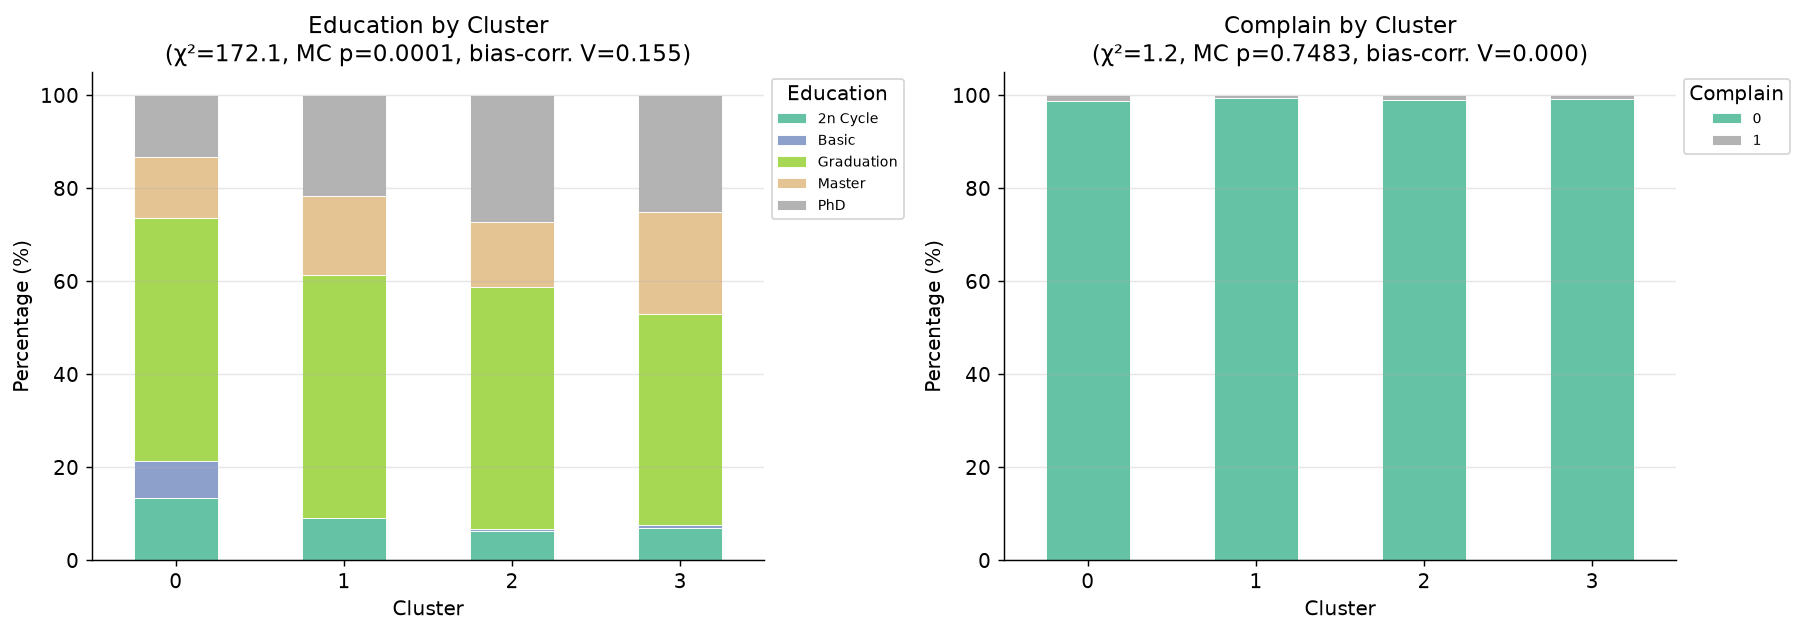

In [18]:
# ── Contingency table: Education × Cluster ────────────────────────────────────

# ── Stacked bar charts ────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (col, chi2, p, v) in zip(axes, [
    ("Education", chi2_edu, p_edu, v_edu),
    ("Complain",  chi2_comp, p_comp, v_comp),
]):
    ct_pct = pd.crosstab(df["cluster"], df[col], normalize="index") * 100
    ct_pct.plot(kind="bar", stacked=True, ax=ax, colormap="Set2",
                edgecolor="white", lw=0.5)
    ax.set(xlabel="Cluster", ylabel="Percentage (%)",
           title=f"{col} by Cluster\n(χ²={chi2:.1f}, MC p={p:.4f}, bias-corr. V={v:.3f})")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    ax.legend(title=col, bbox_to_anchor=(1,1), loc="upper left", fontsize=8)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("plots/external_validation.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
# ── Save cluster labels for Section 3 ─────────────────────────────────────────
labels_out = df[["ID", "cluster"]]
labels_out.to_csv("22_cluster_labels.csv", index=False)
print(f"Saved 22_cluster_labels.csv: {labels_out.shape}, columns = {list(labels_out.columns)}")
print(labels_out["cluster"].value_counts().sort_index().to_string())

Saved 22_cluster_labels.csv: (2236, 2), columns = ['ID', 'cluster']
cluster
0    592
1    530
2    518
3    596


### 7.3 Results and Why Significance Tests on the Clustering Features Prove Nothing

**Education** (no expected count < 5, min expected 12.5, so the asymptotic test is valid):
χ² = 172.1, df = 12, asymptotic p = 1.7×10⁻³⁰, Monte-Carlo p ≤ 1×10⁻⁴ (no permutation out of
10,000 reached the observed χ²). Standard V = 0.160, bias-corrected V = 0.155 → a **significant but
weak** association. The main driver: cluster 0 (Young Budget Browsers) contains 47 of the 54
*Basic*-education customers (expected 14.3) and fewer *PhD* holders than expected (79 vs 128),
while clusters 2 and 3 have more PhDs than expected.

**Complain**: 2 of 8 expected counts are below 5 (min 4.63), so the asymptotic p-value is
questionable; the Monte-Carlo permutation p-value is used instead. χ² = 1.25, df = 3,
asymptotic p = 0.741, **Monte-Carlo p = 0.748** → not significant. Standard V = 0.024,
bias-corrected V = 0.000. Complaint behaviour is spread uniformly across the segments.

**Why tests on the clustering features themselves are circular:**
If we ran a t-test / ANOVA on *Income_Clean*, *Total_Spending* or any other feature **used to form
the clusters**, we would trivially find p ≈ 0. K-Means explicitly chooses the partition that
maximises the separation of cluster means on those features, so the clusters differ on them **by
construction** — even on pure noise, K-Means would produce groups with significantly different
means. The null hypothesis of the test (groups drawn independently of the feature) is violated by
the procedure itself, so the p-value measures only that the algorithm did its job.
Variables that the algorithm never saw (Education, Complain) are an honest check: Education
shows real (if weak) alignment, Complain shows none.

## 8. Summary

| Item | Result |
|---|---|
| Features (8, standardised) | Age, Income_Clean, Total_Spending, Total_Purchases, Total_Children, Customer_Tenure, Recency, NumWebVisitsMonth |
| Custom vs sklearn (k=4, n_init=15) | Inertia 9,798.13 vs 9,798.00 (ratio 1.00001); ARI 0.946 (independent inits), 1.000 when sklearn starts from our centroids |
| Silhouette peak | k=2 (0.289); flat ≈ 0.16–0.17 for k ≥ 4 |
| Elbow | Weak — no clear elbow, mild flattening after k=4 |
| Stability at k=4 | Seed ARI 0.932, bootstrap ARI 0.850; drops to 0.760 / 0.601 at k=5 |
| **Chosen k** | **4** (largest stable k + business usability) |
| Final model (k=4) | sizes 592 / 530 / 518 / 596; silhouette 0.169, Davies–Bouldin 1.88, Calinski–Harabász 614.3 |
| Personas | 0 Young Budget Browsers · 1 Affluent Child-free Big Spenders · 2 Loyal Multichannel Deal-Seekers · 3 New Budget Families |
| Education × cluster | χ²=172.1, df=12, p=1.7×10⁻³⁰ (MC p ≤ 1×10⁻⁴); V=0.160 (standard) / 0.155 (bias-corrected) — significant, weak |
| Complain × cluster | χ²=1.25, df=3, MC p=0.748 (asymptotic 0.741); V=0.024 / 0.000 — not significant |
| Output for Section 3 | `22_cluster_labels.csv` (columns `ID`, `cluster`) |